In [1]:
import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "3"
import torch
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
import matplotlib as plt
import torch
import random
from transformers import CLIPProcessor, CLIPModel
from PIL import Image
sys.path.append('../src')
from utils import *
from matplotlib.lines import Line2D
import matplotlib as mpl
import math
import matplotlib.image as mpimg
import scipy.stats as stats
import scipy as sp
from sklearn.decomposition import PCA
from scipy.stats import pearsonr,binom,linregress
from ast import literal_eval
import json
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import gaussian_kde
from matplotlib.patches import Ellipse
import seaborn as sns
import matplotlib.ticker as mtick
os.chdir("..")

# Load CLIP model and processor
model = CLIPModel.from_pretrained("openai/clip-vit-large-patch14").to("cuda")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")


/export/raid1/home/kneel027/mamba/envs/SS/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`text_config_dict` is provided which will be used to initialize `CLIPTextConfig`. The value `text_config["id2label"]` will be overriden.


# Processed subject reports of their subjective content during the conceptual imagery trials

In [2]:
reports = {1: {
                12: "square wave gratings of various orientations covering the full square",
                13: "single zebra, typically to the left. Covering only 50% or less of the image",
                14: "a chimpanzee facing towards me, centered. Later on a cat facing leftward. Much smaller, maybe 20% of the screen.",
                15: "a large lemon (maybe 40% of the image area) centered. Later on a cartoony image of a smiling sun with flames extending outward and circling around. Also quite large. Occasionally a banana.",
                16: "a single banana curving around the center. Covered maybe 15% of the image. Later on a small bunches of bananas. Quite small, also maybe 10-15% of the area.",
                17: "a large pineapple centered, covering about 50% of the image area. Sometimes grapes, and a couple of times a banana."
            },
            2: {
                12: "vertical black and white stripes mostly on the left side",
                13: "black and white striped zebra facing to the left, four legs, rounded nose, and pointy ears",
                14: "my dog (a black Great Dane) straight on, his eyes, ears, and a close up on his nose, adoption photo",
                15: "yellow cloth hanging from a clothes line",
                16: "banana, stem of the banana in the upper left quadrant of the image, body of the banana centered, one crease running from the stem to the bottom of the banana",
                17: "bowl of apples and oranges on a table"
            },
            3: {
                12: "vertical stripes across the whole square",
                13: "zebra standing in the center, facing left",
                14: "a golden retriever, head and shoulders, smiling. A cartoon-y yellow lab",
                15: "the whole square filled with the color yellow",
                16: "4 bananas, hanging from a black banana hanger",
                17: "an apple, an orange,  some bananas, and then finally all three types of fruit in a fruit bowl." 
            },
            4: {
                12: "a road closure sign. black-white gratings, like a Gabor patch.",
                13: "zebras from different angles, sometimes one zebra sometimes multiple zebras.",
                14: "dogs, cows",
                15: "yellow square, a banana",
                16: "various bananas, sometimes one sometimes multiple. banana section of a grocery store",
                17: "different kinds of bananas or apples in a bowl"
            },
            5: {
                12: "a zebra, a zebra crossing or flags",
                13: "zebra side profile with head facing left",
                14: "zebra side profile with head facing left",
                15: "a banana or a yellow raincoat",
                16: "one large banana with stem at top right or bunches of bananas at a stall",
                17: "either bananas or the orange cut into half picture"
            },
            6: {
                12: "Three black vertical lines that came down from the top one at a time",
                13: "Two zebras one in front of and slightly behind the other. The one in front with head out of frame",
                14: "An elephant head on the right and the skull of an elephant on the left",
                15: "a yellow square",
                16: "a small banana on an L shaped kitchen counter",
                17: "a very ripe, red mango"
            },
            7: {
                12: "a where's waldo shirt",
                13: "a zebras head",
                14: "a dog panting, a bear",
                15: "a yellow rain jacket",
                16: "a single curved banana",
                17: "a single fruit: apple, pear"
            },
            8: {
                12: "black and white thick stripes",
                13: "one zebra in the left side looking away",
                14: "a golden retriever dog sitting with his face towards me",
                15: "a yellow square",
                16: "a bunch of yellow bananas",
                17: "a bowl of fruit in the left corner of the image filled with cantaloupe and grapefruit"
            }
            }

# Subjective reports that identified different content at different temporal points of the experiment, we can potentially analyze these differently by averaging across different trial repetitions

In [3]:
# Split reports:
split_reports = {
            1: {
                14: ["a chimpanzee facing towards me centered", "a cat facing leftward, smaller, maybe 20% of the image"],
                15: ["a large lemon (maybe 40% of the image area) centered.", "A cartoony image of a smiling sun with flames extending outward and circling around. Also quite large.", "a banana"],
                16: ["a single banana curving around the center. Covered maybe 15% of the image.", "small bunches of bananas. Quite small, also maybe 10-15% of the area."],
            },
            3: {
                14: ["a golden retriever, head and shoulders, smiling", "A cartoon-y yellow lab"],
                17: ["an apple", "an orange", "some bananas", "apples, oranges, and bananas in a fruit bowl"]
            }
}

# Create CLIP vectors for all reconstructions and text captions, and make a dataframe to organize

In [19]:
image_clips = []
text_clips = []
df_list = []
for mode in ['vision', 'imagery']:
    recon_path = f"/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/{mode}/"
    for s in tqdm(range(1,9)):
        for i in tqdm(range(18)):
            text_embeddings = None
            if i > 11 and mode == 'imagery':
                text_inputs = processor(text=reports[s][i], return_tensors="pt", padding=True).to("cuda")
                with torch.no_grad():
                    text_embeddings = model.get_text_features(input_ids=text_inputs['input_ids'], attention_mask=text_inputs['attention_mask'])
                text_embeddings = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)
                text_clips.append(text_embeddings.to("cpu"))
            if text_embeddings is not None:
                text_embedding_id = len(text_clips)-1
            else:
                text_embedding_id = None
            if s in [1,2,5,7]:
                for method in ["mindeye", "boi-v2.1", "braindiffuser", "boi-v2.3", "mindeye2", "takagi"]:
                    for j in range(10):
                        image_inputs = processor(images=[Image.open(f"{recon_path}{method}/subject{s}/{i}/{j}.png")], return_tensors="pt", padding=True).to("cuda")
                        with torch.no_grad():
                            image_embeddings = model.get_image_features(**{k: v for k, v in image_inputs.items() if k in processor.model_input_names and 'pixel_values' in k})
                        image_embeddings = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)
                        image_clips.append(image_embeddings.to("cpu"))
                        similarity = None
                        if i > 11 and mode == 'imagery':
                            # Compute the cosine similarity
                            similarity = cosine_similarity(text_embeddings.cpu().numpy(), image_embeddings.cpu().numpy())[0][0]
                        # print(f"Similarity between text_embeddings and image_embeddings: {similarities}")
                        df_list.append({"subject": s, "mode" : mode, "image": i, "rep": j, "method": method, "image_embedding_id": len(image_clips)-1, "text_embedding_id": text_embedding_id, "similarity" : similarity})
            else:
                print(f"adding row to DF: {s}, {mode}, {i}, {text_embedding_id}")
                df_list.append({"subject": s, "mode" : mode, "image": i, "text_embedding_id": text_embedding_id})
                

100%|██████████| 18/18 [00:00<00:00, 169657.24it/s]


adding row to DF: 3, vision, 0, None
adding row to DF: 3, vision, 1, None
adding row to DF: 3, vision, 2, None
adding row to DF: 3, vision, 3, None
adding row to DF: 3, vision, 4, None
adding row to DF: 3, vision, 5, None
adding row to DF: 3, vision, 6, None
adding row to DF: 3, vision, 7, None
adding row to DF: 3, vision, 8, None
adding row to DF: 3, vision, 9, None
adding row to DF: 3, vision, 10, None
adding row to DF: 3, vision, 11, None
adding row to DF: 3, vision, 12, None
adding row to DF: 3, vision, 13, None
adding row to DF: 3, vision, 14, None
adding row to DF: 3, vision, 15, None
adding row to DF: 3, vision, 16, None
adding row to DF: 3, vision, 17, None


100%|██████████| 18/18 [00:00<00:00, 185042.82it/s]


adding row to DF: 4, vision, 0, None
adding row to DF: 4, vision, 1, None
adding row to DF: 4, vision, 2, None
adding row to DF: 4, vision, 3, None
adding row to DF: 4, vision, 4, None
adding row to DF: 4, vision, 5, None
adding row to DF: 4, vision, 6, None
adding row to DF: 4, vision, 7, None
adding row to DF: 4, vision, 8, None
adding row to DF: 4, vision, 9, None
adding row to DF: 4, vision, 10, None
adding row to DF: 4, vision, 11, None
adding row to DF: 4, vision, 12, None
adding row to DF: 4, vision, 13, None
adding row to DF: 4, vision, 14, None
adding row to DF: 4, vision, 15, None
adding row to DF: 4, vision, 16, None
adding row to DF: 4, vision, 17, None


100%|██████████| 18/18 [00:00<00:00, 162011.74it/s]


adding row to DF: 6, vision, 0, None
adding row to DF: 6, vision, 1, None
adding row to DF: 6, vision, 2, None
adding row to DF: 6, vision, 3, None
adding row to DF: 6, vision, 4, None
adding row to DF: 6, vision, 5, None
adding row to DF: 6, vision, 6, None
adding row to DF: 6, vision, 7, None
adding row to DF: 6, vision, 8, None
adding row to DF: 6, vision, 9, None
adding row to DF: 6, vision, 10, None
adding row to DF: 6, vision, 11, None
adding row to DF: 6, vision, 12, None
adding row to DF: 6, vision, 13, None
adding row to DF: 6, vision, 14, None
adding row to DF: 6, vision, 15, None
adding row to DF: 6, vision, 16, None
adding row to DF: 6, vision, 17, None


 75%|███████▌  | 6/8 [02:05<00:41, 20.91s/it]


KeyboardInterrupt: 

In [3]:
version = 2
df = pd.DataFrame(df_list)
image_clips = torch.stack(image_clips)
text_clips = torch.stack(text_clips)
torch.save(image_clips, f"output/mental_imagery_paper_b3/image_clips_v{version}.pt")
torch.save(text_clips, f"output/mental_imagery_paper_b3/text_clips_v{version}.pt")
df.to_csv(f"output/mental_imagery_paper_b3/subjective_embeddings_v{version}.csv", index=False)

NameError: name 'df_list' is not defined

In [6]:
# Group the dataframe by the 'method' column and calculate the mean similarity for each group
average_similarity = df.groupby('method')['similarity'].mean()

# Print the average similarity for each method
print(average_similarity)

method
boi-v2.1         0.139615
boi-v2.3         0.121061
braindiffuser    0.128457
mindeye          0.139481
mindeye2         0.102397
takagi           0.099725
Name: similarity, dtype: float64


In [4]:
version = 2
# Load the saved image clips
image_clips = torch.load(f"output/mental_imagery_paper_b3/image_clips_v{version}.pt")
# Load the saved text clips
text_clips = torch.load(f"output/mental_imagery_paper_b3/text_clips_v{version}.pt")
# Load the saved dataframe
df = pd.read_csv(f"output/mental_imagery_paper_b3/subjective_embeddings_v{version}.csv")

# Create an image-text clip subject alignment matrix figure

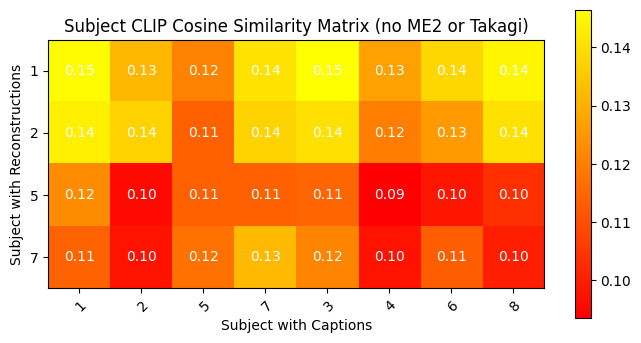

In [27]:


# df = df[df['image'].isin([13,14, 16, 17])]

# Initialize a dictionary to store the subject-wise similarities
subject_similarities = np.zeros((4, 8))
y_axis_subj_list = [1,2,5,7]
x_axis_subj_list = [1,2,5,7,3,4,6,8]
# Iterate through the subjects that have reconstructions
for s1, subject1 in enumerate(y_axis_subj_list):
    # Iterate through the subjects that have captions
    for s2, subject2 in enumerate(x_axis_subj_list):
        # Filter the dataframe for the current subject
        subject1_data = df[(df['subject'] == subject1) & (df['method'] != "mindeye2") & (df['method'] != "takagi") & (df['image'] > 11) & (df['mode'] == 'imagery')]
        subject2_data = df[(df['subject'] == subject2) & (df['image'] > 11) & (df['mode'] == 'imagery')]
        # print(subject2, subject2_data)
        # Initialize lists to store similarities for this subject
        similarities = []
        
        for _, row in subject1_data.iterrows():
            # Get the image and text embedding IDs
            image_id = int(row['image_embedding_id'])
            # Find the row in subject2_data that matches the specified columns
            matching_row = subject2_data[
                (subject2_data['image'] == row['image'])
            ]
            
            # Get the index of the matching row
            matching_row_index = matching_row.index[0]
            
            # print("subject1: ", row, "\nsubject2: ", subject2_data.loc[matching_row_index])
            # Access the text_embedding_id from the matching row
            text_id = int(subject2_data.loc[matching_row_index, 'text_embedding_id'])
            
            # Extract the corresponding CLIP vectors
            image_vector = image_clips[image_id].numpy().reshape(1, -1)
            text_vector = text_clips[text_id].numpy().reshape(1, -1)
            
            # Compute the cosine similarity
            similarity = cosine_similarity(image_vector, text_vector).item()
            similarities.append(similarity)
        
        # Average the similarities for this subject
        # print(subject1, subject2, len(similarities), np.mean(similarities))
        subject_similarities[s1,s2] = np.mean(similarities)

# Create the RDM by comparing each subject with every other subject
# Create a figure and axis
fig, ax = plt.subplots(figsize=(8, 4))

# Plot the similarity matrix as a heatmap
im = ax.imshow(subject_similarities, cmap='autumn')

# Add a colorbar
cbar = ax.figure.colorbar(im, ax=ax)

# Set the axis labels
ax.set_xticks(np.arange(subject_similarities.shape[1]))
ax.set_yticks(np.arange(subject_similarities.shape[0]))
ax.set_xticklabels([str(x) for x in x_axis_subj_list])
ax.set_yticklabels([str(y) for y in y_axis_subj_list])

# Rotate the x-axis labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Set the title and axis labels
ax.set_title("Subject CLIP Cosine Similarity Matrix (no ME2 or Takagi)")
ax.set_xlabel("Subject with Captions")
ax.set_ylabel("Subject with Reconstructions")

# Loop over data dimensions and create text annotations
for i in range(subject_similarities.shape[0]):
    for j in range(subject_similarities.shape[1]):
        text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

# Show the plot
plt.show()


# Create an text-text clip subject alignment matrix figure

torch.Size([48, 1, 768])


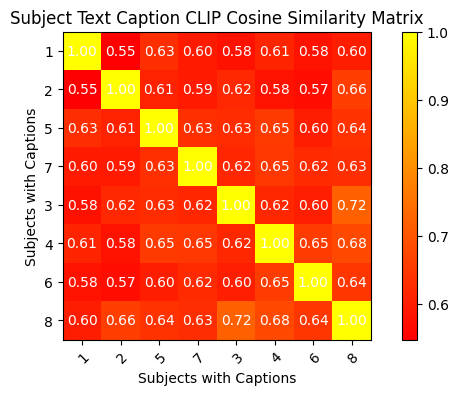

In [19]:

# Initialize a dictionary to store the subject-wise similarities
subject_similarities = np.zeros((8, 8))
y_axis_subj_list = [1,2,5,7,3,4,6,8]
x_axis_subj_list = [1,2,5,7,3,4,6,8]
# Iterate through the subjects that have reconstructions
for s1, subject1 in enumerate(y_axis_subj_list):
    # Iterate through the subjects that have captions
    for s2, subject2 in enumerate(x_axis_subj_list):
        # Filter the dataframe for the current subject
        subject1_data = df[(df['subject'] == subject1) & (df['image'] > 11) & (df['mode'] == 'imagery')]
        subject2_data = df[(df['subject'] == subject2) & (df['image'] > 11) & (df['mode'] == 'imagery')]
        # Initialize lists to store similarities for this subject
        similarities = []
        for _, row in subject1_data.iterrows():
            # Get the image and text embedding IDs
            text_id1 = int(row['text_embedding_id'])
            # Find the row in subject2_data that matches the specified columns
            matching_row = subject2_data[
                (subject2_data['subject'] == subject2) &
                (subject2_data['image'] == row['image'])
            ]

            # Get the index of the matching row
            matching_row_index = matching_row.index[0]
            
            # print("subject1: ", row, "\nsubject2: ", subject2_data.loc[matching_row_index])
            # Access the text_embedding_id from the matching row
            text_id2 = int(subject2_data.loc[matching_row_index, 'text_embedding_id'])
            
            # Extract the corresponding CLIP vectors
            text_vector1 = text_clips[text_id1].numpy().reshape(1, -1)
            text_vector2 = text_clips[text_id2].numpy().reshape(1, -1)
            
            # Compute the cosine similarity
            similarity = cosine_similarity(text_vector1, text_vector2).item()
            similarities.append(similarity)
        
        # Average the similarities for this subject
        # print(subject1, subject2, len(similarities), np.mean(similarities))
        subject_similarities[s1,s2] = np.mean(similarities)

# Create the RDM by comparing each subject with every other subject
# Create a figure and axis
fig, ax = plt.subplots(figsize=(8, 4))

# Plot the similarity matrix as a heatmap
im = ax.imshow(subject_similarities, cmap='autumn')

# Add a colorbar
cbar = ax.figure.colorbar(im, ax=ax)

# Set the axis labels
ax.set_xticks(np.arange(subject_similarities.shape[1]))
ax.set_yticks(np.arange(subject_similarities.shape[0]))
ax.set_xticklabels([str(x) for x in x_axis_subj_list])
ax.set_yticklabels([str(y) for y in y_axis_subj_list])

# Rotate the x-axis labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Set the title and axis labels
ax.set_title("Subject Text Caption CLIP Cosine Similarity Matrix")
ax.set_xlabel("Subjects with Captions")
ax.set_ylabel("Subjects with Captions")

# Loop over data dimensions and create text annotations
for i in range(subject_similarities.shape[0]):
    for j in range(subject_similarities.shape[1]):
        text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

# Show the plot
plt.show()


# Create an image-image clip subject alignment matrix figure

100%|██████████| 4/4 [02:20<00:00, 35.09s/it]


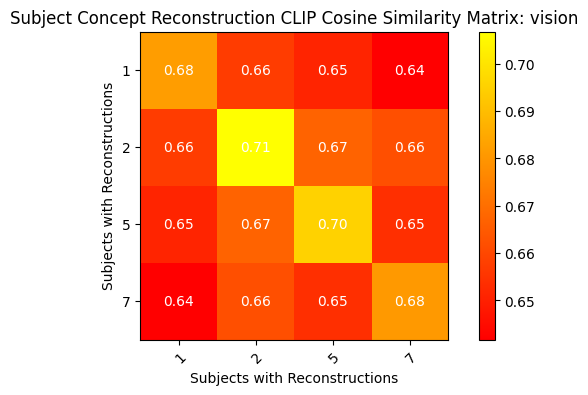

100%|██████████| 4/4 [02:23<00:00, 35.76s/it]


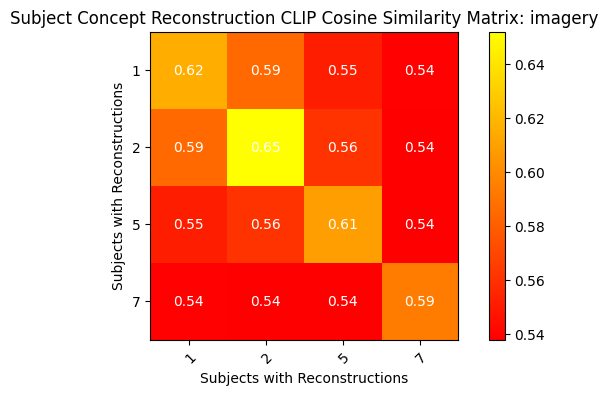

In [56]:
for mode in ['vision', 'imagery']:
    # Initialize a dictionary to store the subject-wise similarities
    subject_similarities = np.zeros((4, 4))
    y_axis_subj_list = [1,2,5,7]
    x_axis_subj_list = [1,2,5,7]
    # Iterate through the subjects that have reconstructions
    for s1, subject1 in enumerate(tqdm(y_axis_subj_list)):
        # Iterate through the subjects that have captions
        for s2, subject2 in enumerate(x_axis_subj_list):
            # Filter the dataframe for the current subject
            subject1_data = df[(df['subject'] == subject1) & (df['image'] > 11)  & (df['mode'] == mode)]
            subject2_data = df[(df['subject'] == subject2) & (df['image'] > 11)  & (df['mode'] == mode)]
            # Initialize lists to store similarities for this subject
            similarities = []
            for _, row in subject1_data.iterrows():
                # Get the image and text embedding IDs
                image_id1 = int(row['image_embedding_id'])
                # Find the row in subject2_data that matches the specified columns
                matching_rows = subject2_data[
                    (subject2_data['subject'] == subject2) &
                    (subject2_data['image'] == row['image'])
                ]
                for _, row in matching_rows.iterrows():
                    # Get the image and text embedding IDs
                    image_id2 = int(row['image_embedding_id'])
                
                    # Extract the corresponding CLIP vectors
                    image_vector1 = image_clips[image_id1].numpy().reshape(1, -1)
                    image_vector2 = image_clips[image_id2].numpy().reshape(1, -1)
                
                    # Compute the cosine similarity
                    similarity = cosine_similarity(image_vector1, image_vector2).item()
                    similarities.append(similarity)
            
            # Average the similarities for this subject
            # print(subject1, subject2, len(similarities), np.mean(similarities))
            subject_similarities[s1,s2] = np.mean(similarities)

    # Create the RDM by comparing each subject with every other subject
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(8, 4))

    # Plot the similarity matrix as a heatmap
    im = ax.imshow(subject_similarities, cmap='autumn')

    # Add a colorbar
    cbar = ax.figure.colorbar(im, ax=ax)

    # Set the axis labels
    ax.set_xticks(np.arange(subject_similarities.shape[1]))
    ax.set_yticks(np.arange(subject_similarities.shape[0]))
    ax.set_xticklabels([str(x) for x in x_axis_subj_list])
    ax.set_yticklabels([str(y) for y in y_axis_subj_list])

    # Rotate the x-axis labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Set the title and axis labels
    ax.set_title(f"Subject Concept Reconstruction CLIP Cosine Similarity Matrix: {mode}")
    ax.set_xlabel("Subjects with Reconstructions")
    ax.set_ylabel("Subjects with Reconstructions")

    # Loop over data dimensions and create text annotations
    for i in range(subject_similarities.shape[0]):
        for j in range(subject_similarities.shape[1]):
            text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

    # Show the plot
    plt.show()


100%|██████████| 4/4 [00:01<00:00,  2.67it/s]


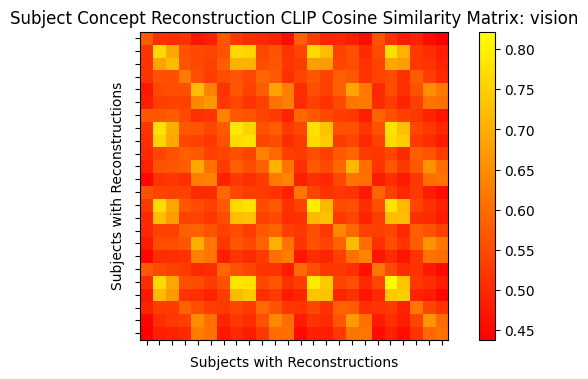

100%|██████████| 4/4 [00:01<00:00,  2.62it/s]


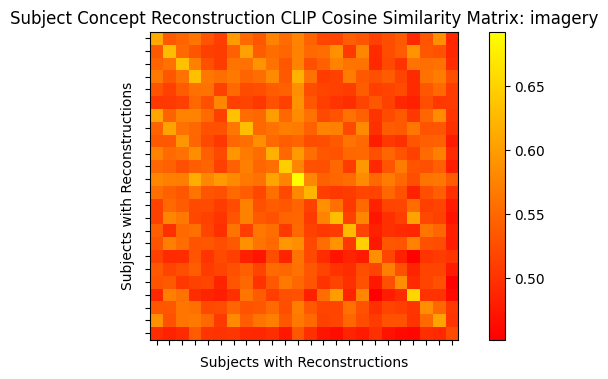

In [59]:
for mode in ['vision', 'imagery']:
    # Initialize a dictionary to store the subject-wise similarities
    subject_similarities = np.zeros((24, 24))
    y_axis_subj_list = [1,2,5,7]
    x_axis_subj_list = [1,2,5,7]
    # Iterate through the subjects that have reconstructions
    for s1, subject1 in enumerate(tqdm(y_axis_subj_list)):
        for i1, image1 in enumerate(range(12,18)):
            # Iterate through the subjects that have captions
            for s2, subject2 in enumerate(x_axis_subj_list):
                for i2, image2 in enumerate(range(12,18)):
                    # Filter the dataframe for the current subject
                    subject1_data = df[(df['subject'] == subject1) & (df['image'] == image1) & (df['mode'] == mode)]
                    subject2_data = df[(df['subject'] == subject2) & (df['image'] == image2) & (df['mode'] == mode)]
                    # Initialize lists to store similarities for this subject
                    similarities = []
                    image_ids1 = subject1_data['image_embedding_id'].tolist()
                    random.shuffle(image_ids1)
                    # print(image_ids1)
                    image_vector1 = image_clips[image_ids1].numpy().reshape(1, -1)
                    image_ids2 = subject2_data['image_embedding_id'].tolist()
                    random.shuffle(image_ids2)
                    # print(image_ids2)
                    image_vector2 = image_clips[image_ids2].numpy().reshape(1, -1)
                    # for _, row in subject1_data.iterrows():
                    #     # Get the image and text embedding IDs
                    #     image_id1 = int(row['image_embedding_id'])
                    #     # Find the row in subject2_data that matches the specified columns
                    #     matching_rows = subject2_data[
                    #         (subject2_data['subject'] == subject2) &
                    #         (subject2_data['image'] == row['image'])
                    #     ]
                    #     for _, row in matching_rows.iterrows():
                    #         # Get the image and text embedding IDs
                    #         image_id2 = int(row['image_embedding_id'])
                        
                    #         # Extract the corresponding CLIP vectors
                    #         image_vector1 = image_clips[image_id1].numpy().reshape(1, -1)
                    #         image_vector2 = image_clips[image_id2].numpy().reshape(1, -1)
                        
                    # Compute the cosine similarity
                    similarities.append(cosine_similarity(image_vector1, image_vector2).item())
                    
                    # Average the similarities for this subject
                    # print(subject1, subject2, len(similarities), np.mean(similarities))
                    subject_similarities[s1*6 + i1,s2*6 + i2] = np.mean(similarities)

    # Create the RDM by comparing each subject with every other subject
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(8, 4))

    # Plot the similarity matrix as a heatmap
    im = ax.imshow(subject_similarities, cmap='autumn')

    # Add a colorbar
    cbar = ax.figure.colorbar(im, ax=ax)

    # Set the axis labels
    ax.set_xticks(np.arange(subject_similarities.shape[1]))
    ax.set_yticks(np.arange(subject_similarities.shape[0]))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    # ax.set_xticklabels([str(x) for x in x_axis_subj_list])
    # ax.set_yticklabels([str(y) for y in y_axis_subj_list])

    # Rotate the x-axis labels
    # plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Set the title and axis labels
    ax.set_title(f"Subject Concept Reconstruction CLIP Cosine Similarity Matrix: {mode}")
    ax.set_xlabel("Subjects with Reconstructions")
    ax.set_ylabel("Subjects with Reconstructions")

    # # Loop over data dimensions and create text annotations
    # for i in range(subject_similarities.shape[0]):
    #     for j in range(subject_similarities.shape[1]):
    #         text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

    # Show the plot
    plt.show()


100%|██████████| 4/4 [00:13<00:00,  3.45s/it]


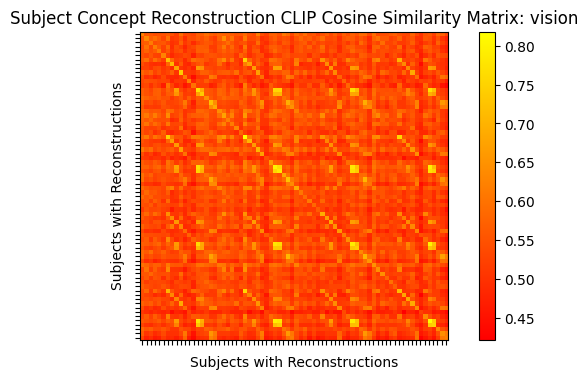

100%|██████████| 4/4 [00:13<00:00,  3.45s/it]


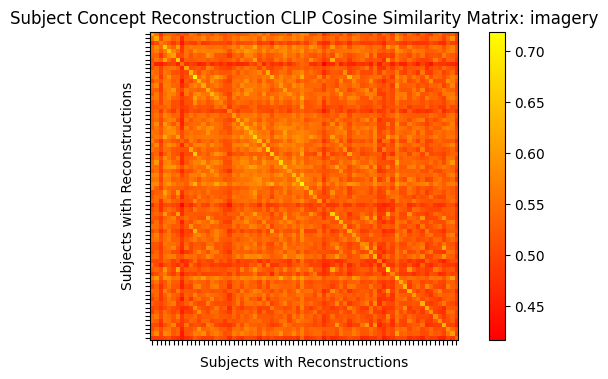

In [62]:
for mode in ['vision', 'imagery']:
    # Initialize a dictionary to store the subject-wise similarities
    subject_similarities = np.zeros((72, 72))
    y_axis_subj_list = [1,2,5,7]
    x_axis_subj_list = [1,2,5,7]
    # Iterate through the subjects that have reconstructions
    for s1, subject1 in enumerate(tqdm(y_axis_subj_list)):
        for i1, image1 in enumerate(range(18)):
            # Iterate through the subjects that have captions
            for s2, subject2 in enumerate(x_axis_subj_list):
                for i2, image2 in enumerate(range(18)):
                    # Filter the dataframe for the current subject
                    subject1_data = df[(df['subject'] == subject1) & (df['image'] == image1) & (df['mode'] == mode)]
                    subject2_data = df[(df['subject'] == subject2) & (df['image'] == image2) & (df['mode'] == mode)]
                    # Initialize lists to store similarities for this subject
                    similarities = []
                    image_ids1 = subject1_data['image_embedding_id'].tolist()
                    random.shuffle(image_ids1)
                    # print(image_ids1)
                    image_vector1 = image_clips[image_ids1].numpy().reshape(1, -1)
                    image_ids2 = subject2_data['image_embedding_id'].tolist()
                    random.shuffle(image_ids2)
                    # print(image_ids2)
                    image_vector2 = image_clips[image_ids2].numpy().reshape(1, -1)
                    # for _, row in subject1_data.iterrows():
                    #     # Get the image and text embedding IDs
                    #     image_id1 = int(row['image_embedding_id'])
                    #     # Find the row in subject2_data that matches the specified columns
                    #     matching_rows = subject2_data[
                    #         (subject2_data['subject'] == subject2) &
                    #         (subject2_data['image'] == row['image'])
                    #     ]
                    #     for _, row in matching_rows.iterrows():
                    #         # Get the image and text embedding IDs
                    #         image_id2 = int(row['image_embedding_id'])
                        
                    #         # Extract the corresponding CLIP vectors
                    #         image_vector1 = image_clips[image_id1].numpy().reshape(1, -1)
                    #         image_vector2 = image_clips[image_id2].numpy().reshape(1, -1)
                        
                    # Compute the cosine similarity
                    similarities.append(cosine_similarity(image_vector1, image_vector2).item())
                    
                    # Average the similarities for this subject
                    # print(subject1, subject2, len(similarities), np.mean(similarities))
                    subject_similarities[s1*18 + i1,s2*18 + i2] = np.mean(similarities)

    # Create the RDM by comparing each subject with every other subject
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(8, 4))

    # Plot the similarity matrix as a heatmap
    im = ax.imshow(subject_similarities, cmap='autumn')

    # Add a colorbar
    cbar = ax.figure.colorbar(im, ax=ax)

    # Set the axis labels
    ax.set_xticks(np.arange(subject_similarities.shape[1]))
    ax.set_yticks(np.arange(subject_similarities.shape[0]))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    # ax.set_xticklabels([str(x) for x in x_axis_subj_list])
    # ax.set_yticklabels([str(y) for y in y_axis_subj_list])

    # Rotate the x-axis labels
    # plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Set the title and axis labels
    ax.set_title(f"Subject Concept Reconstruction CLIP Cosine Similarity Matrix: {mode}")
    ax.set_xlabel("Subjects with Reconstructions")
    ax.set_ylabel("Subjects with Reconstructions")

    # # Loop over data dimensions and create text annotations
    # for i in range(subject_similarities.shape[0]):
    #     for j in range(subject_similarities.shape[1]):
    #         text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

    # Show the plot
    plt.show()


100%|██████████| 6/6 [00:25<00:00,  4.20s/it]


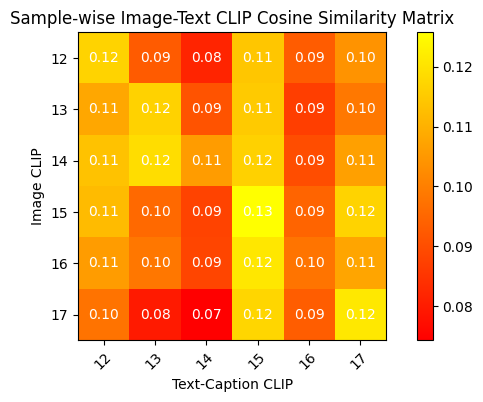

In [91]:

# Initialize a dictionary to store the subject-wise similarities
subject_similarities = np.zeros((6, 6))
y_axis_image_list = [12, 13, 14, 15, 16, 17]
x_axis_image_list = [12, 13, 14, 15, 16, 17]
# Iterate through the subjects that have reconstructions
for i1, image1 in enumerate(tqdm(y_axis_image_list)):
    # Iterate through the subjects that have captions
    for i2, image2 in enumerate(x_axis_image_list):
        # Filter the dataframe for the current subject
        image1_data = df[(df['image'] == image1) & (df['mode'] == "imagery")]
        image2_data = df[(df['image'] == image2) & (df['mode'] == "imagery")]
        # Initialize lists to store similarities for this subject
        similarities = []
        # Get the rows where "image_embedding_id" is not None
        image1_data = image1_data[image1_data['image_embedding_id'].notnull()]
        # Iterate through the filtered rows
        for _, row in image1_data.iterrows():
            # Get the image and text embedding IDs
            image_id = int(row['image_embedding_id'])
            # # Find the row in subject2_data that matches the specified columns
            # matching_rows = image2_data[
            #     # (subject2_data['subject'] == subject2) &
            #     (image2_data['image'] == row['image'])
            # ]
            unique_text_ids = image2_data['text_embedding_id'].unique()
            # Iterate through the unique values
            for text_id in unique_text_ids:
                # Extract the corresponding CLIP vectors
                image_vector = image_clips[image_id].numpy().reshape(1, -1)
                text_vector = text_clips[int(text_id)].numpy().reshape(1, -1)
            
                # Compute the cosine similarity
                similarity = cosine_similarity(image_vector, text_vector).item()
                similarities.append(similarity)
        
        # Average the similarities for this subject
        # print(subject1, subject2, len(similarities), np.mean(similarities))
        subject_similarities[i1,i2] = np.mean(similarities)

# Create the RDM by comparing each subject with every other subject
# Create a figure and axis
fig, ax = plt.subplots(figsize=(8, 4))

# Plot the similarity matrix as a heatmap
im = ax.imshow(subject_similarities, cmap='autumn')

# Add a colorbar
cbar = ax.figure.colorbar(im, ax=ax)

# Set the axis labels
ax.set_xticks(np.arange(subject_similarities.shape[1]))
ax.set_yticks(np.arange(subject_similarities.shape[0]))
ax.set_xticklabels([str(x) for x in x_axis_image_list])
ax.set_yticklabels([str(y) for y in y_axis_image_list])

# Rotate the x-axis labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

# Set the title and axis labels
ax.set_title("Sample-wise Image-Text CLIP Cosine Similarity Matrix")
ax.set_ylabel("Image CLIP")
ax.set_xlabel("Text-Caption CLIP")

# Loop over data dimensions and create text annotations
for i in range(subject_similarities.shape[0]):
    for j in range(subject_similarities.shape[1]):
        text = ax.text(j, i, f"{subject_similarities[i, j]:.2f}", ha="center", va="center", color="w")

# Show the plot
plt.show()


The percentage of times that the strongest value for each row is on the central diagonal is: 75.0%


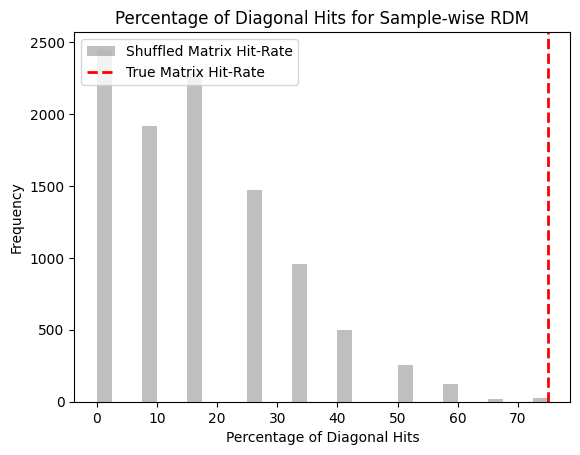

The p-value for the true percent is: 0.0028997100289971


In [93]:
def compute_percent_diagonal(subject_similarities):
    count = 0
    # Iterate through each row of the matrix
    for i in range(subject_similarities.shape[0]):
        # Find the index of the strongest value in the row
        strongest_index = np.argmax(subject_similarities[i])
        
        # Check if the strongest value is on the central diagonal
        if strongest_index == i:
            count += 1
    # Iterate through each row of the matrix
    for i in range(subject_similarities.shape[1]):
        # Find the index of the strongest value in the row
        strongest_index = np.argmax(subject_similarities[:,i])
        
        # Check if the strongest value is on the central diagonal
        if strongest_index == i:
            count += 1
    # Compute the percentage
    percentage = (count / (subject_similarities.shape[0]*2)) * 100
    return percentage

true_percent = compute_percent_diagonal(subject_similarities)
# Print the result
print(f"The percentage of times that the strongest value for each row is on the central diagonal is: {true_percent}%")
shuffled_percents = []
random_subject_similarities = subject_similarities.copy()
for i in range(10000):
    np.random.shuffle(random_subject_similarities)
    random_pct = compute_percent_diagonal(random_subject_similarities)
    shuffled_percents.append(random_pct)

# Plot the null distribution of shuffled correlations
plt.hist(shuffled_percents, bins=30, color='gray', alpha=0.5, label='Shuffled Matrix Hit-Rate')

# Plot a red indicator for the true correlation
plt.axvline(x=true_percent, color='red', linestyle='--', linewidth=2, label='True Matrix Hit-Rate')

# Add a legend
plt.legend(loc='upper left')

# Set the title and labels
plt.title("Percentage of Diagonal Hits for Sample-wise RDM")
plt.xlabel("Percentage of Diagonal Hits")
plt.ylabel("Frequency")


# Show the plot
plt.show()

# Calculate the p-value
p_value = (np.sum(np.array(shuffled_percents) >= true_percent) + 1) / (len(shuffled_percents) + 1)

# Print the p-value
print(f"The p-value for the true percent is: {p_value}")



100%|██████████| 4/4 [00:01<00:00,  2.28it/s]


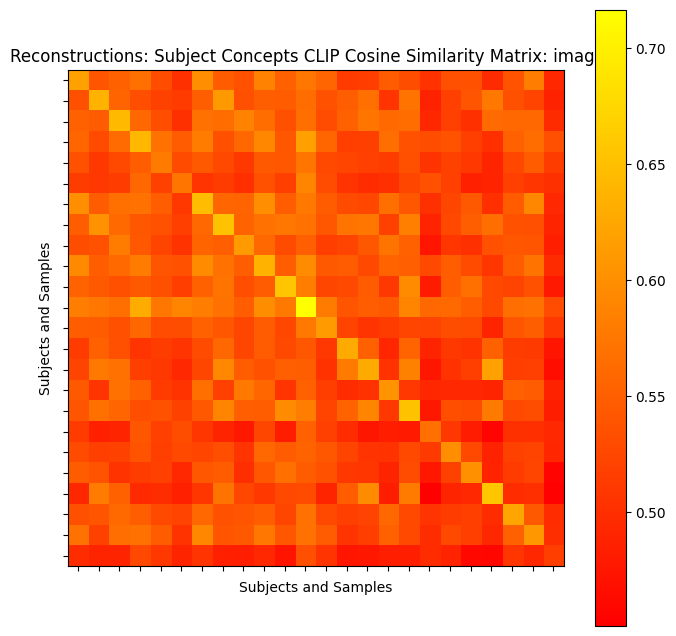

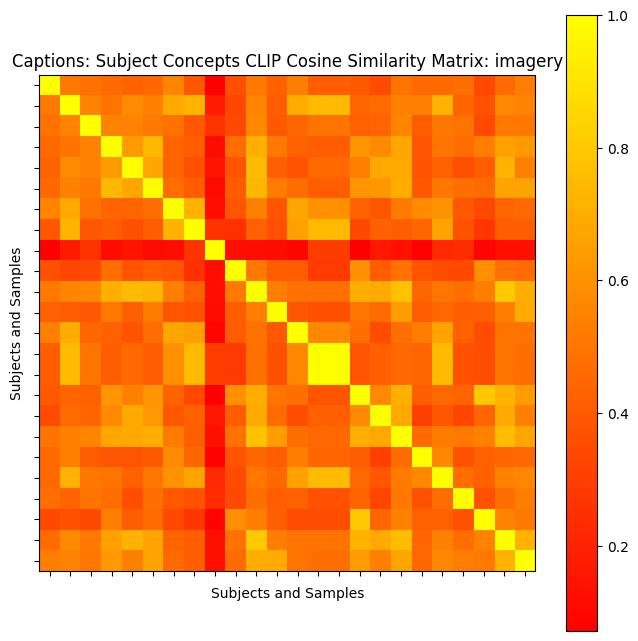

In [9]:
mode = 'imagery'
# Initialize a dictionary to store the subject-wise similarities
subject_similarities_img = np.zeros((24, 24))
subject_similarities_txt = np.zeros((24, 24))
y_axis_subj_list = [1,2,5,7]
x_axis_subj_list = [1,2,5,7]
# Iterate through the subjects that have reconstructions
for s1, subject1 in enumerate(tqdm(y_axis_subj_list)):
    for i1, image1 in enumerate(range(12,18)):
        # Iterate through the subjects that have captions
        for s2, subject2 in enumerate(x_axis_subj_list):
            for i2, image2 in enumerate(range(12,18)):
                # Filter the dataframe for the current subject
                subject1_data = df[(df['subject'] == subject1) & (df['image'] == image1) & (df['mode'] == mode)]
                subject2_data = df[(df['subject'] == subject2) & (df['image'] == image2) & (df['mode'] == mode)]

                image_ids1 = subject1_data['image_embedding_id'].tolist()
                random.shuffle(image_ids1)
                image_ids2 = subject2_data['image_embedding_id'].tolist()
                random.shuffle(image_ids2)
                
                image_vector1 = image_clips[image_ids1].numpy().reshape(1, -1)
                image_vector2 = image_clips[image_ids2].numpy().reshape(1, -1)
                
                text_id1 = int(list(set(subject1_data['text_embedding_id'].tolist()))[0])
                text_id2 = int(list(set(subject2_data['text_embedding_id'].tolist()))[0])
                
                # Extract the corresponding CLIP vectors
                text_vector1 = text_clips[text_id1].numpy().reshape(1, -1)
                text_vector2 = text_clips[text_id2].numpy().reshape(1, -1)
                # print(text_vector1 == text_vector2)
                # Compute the cosine similarity and average the similarities for this subject
                subject_similarities_img[s1*6 + i1,s2*6 + i2] = np.mean(cosine_similarity(image_vector1, image_vector2).item())
                subject_similarities_txt[s1*6 + i1,s2*6 + i2] = np.mean(cosine_similarity(text_vector1, text_vector2).item())

# Create the RDM by comparing each subject with every other subject
# Create a figure and axis for the image similarities
fig, ax = plt.subplots(figsize=(8, 8))
# Plot the similarity matrix as a heatmap
im = ax.imshow(subject_similarities_img, cmap='autumn')
# Add a colorbar
cbar = ax.figure.colorbar(im, ax=ax)
# Set the axis labels
ax.set_xticks(np.arange(subject_similarities_img.shape[1]))
ax.set_yticks(np.arange(subject_similarities_img.shape[0]))
ax.set_xticklabels([])
ax.set_yticklabels([])
# Set the title and axis labels
ax.set_title(f"Reconstructions: Subject Concepts CLIP Cosine Similarity Matrix: {mode}")
ax.set_xlabel("Subjects and Samples")
ax.set_ylabel("Subjects and Samples")
plt.show()

# Create a figure and axis
fig, ax = plt.subplots(figsize=(8, 8))

# Plot the similarity matrix as a heatmap
im = ax.imshow(subject_similarities_txt, cmap='autumn')

# Add a colorbar
cbar = ax.figure.colorbar(im, ax=ax)

# Set the axis labels
ax.set_xticks(np.arange(subject_similarities_txt.shape[1]))
ax.set_yticks(np.arange(subject_similarities_txt.shape[0]))
ax.set_xticklabels([])
ax.set_yticklabels([])

# Set the title and axis labels
ax.set_title(f"Captions: Subject Concepts CLIP Cosine Similarity Matrix: {mode}")
ax.set_xlabel("Subjects and Samples")
ax.set_ylabel("Subjects and Samples")
plt.show()

# Distribution plot analysis for completely shuffled RDM null distribution

276 276
Pearson correlation of upper triangle: -0.04135712650033205
p-value: 0.4938168434489574


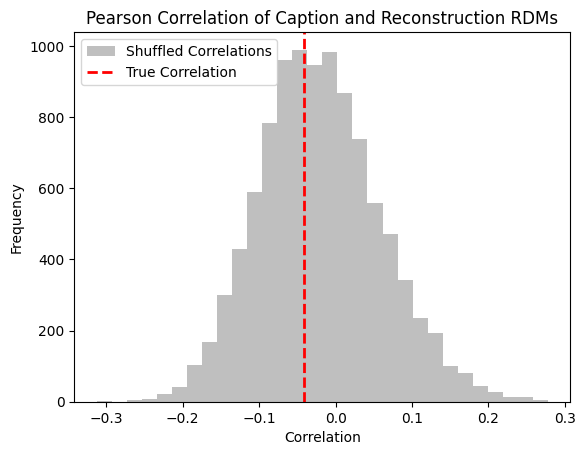

The p-value for the true correlation is: 0.5829417058294171


In [13]:
from scipy.stats import pearsonr

# Flatten the subject similarities matrices, excluding 0 elements
flattened_txt = subject_similarities_txt[np.nonzero(np.triu(subject_similarities_txt, k=1))]
flattened_img = subject_similarities_img[np.nonzero(np.triu(subject_similarities_img, k=1))]
print(len(flattened_txt), len(flattened_img))
true_correlation, p_value = pearsonr(flattened_txt, flattened_img)
print("Pearson correlation of upper triangle:", true_correlation)
print("p-value:", p_value)
shuffled_correlations = []

for i in range(10000):
    perm = np.random.permutation(24)
    randomized_subject_similarities_txt = subject_similarities_txt[:, perm]
    flattened_txt = randomized_subject_similarities_txt[np.nonzero(np.triu(randomized_subject_similarities_txt, k=1))]
    correlation, p_value = pearsonr(flattened_txt, flattened_img)
    # print("Pearson correlation of shuffled upper triangle:", correlation)
    # print("p-value:", p_value)
    shuffled_correlations.append(correlation)

# Plot the null distribution of shuffled correlations
plt.hist(shuffled_correlations, bins=30, color='gray', alpha=0.5, label='Shuffled Correlations')

# Plot a red indicator for the true correlation
plt.axvline(x=true_correlation, color='red', linestyle='--', linewidth=2, label='True Correlation')

# Add a legend
plt.legend(loc='upper left')

# Set the title and labels
plt.title("Pearson Correlation of Caption and Reconstruction RDMs")
plt.xlabel("Correlation")
plt.ylabel("Frequency")


# Show the plot
plt.show()

p_value = (np.sum(np.array(shuffled_correlations) >= true_correlation) + 1) / (len(shuffled_correlations) + 1)
# Print the p-value
print(f"The p-value for the true correlation is: {p_value}")


# Distribution plot analysis for only the subjects being shuffled

Pearson correlation of upper triangle: -0.04135712650033205
p-value: 0.4938168434489574


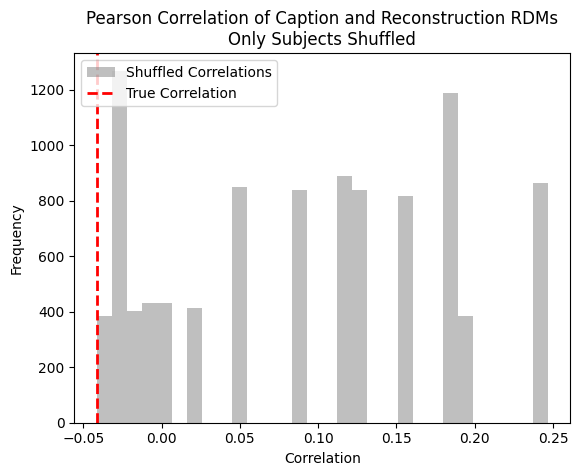

The p-value for the true correlation is: 1.0


In [14]:
from scipy.stats import pearsonr

# Flatten the subject similarities matrices, excluding 0 elements
flattened_txt = subject_similarities_txt[np.nonzero(np.triu(subject_similarities_txt, k=1))]
flattened_img = subject_similarities_img[np.nonzero(np.triu(subject_similarities_img, k=1))]
true_correlation, p_value = pearsonr(flattened_txt, flattened_img)
print("Pearson correlation of upper triangle:", true_correlation)
print("p-value:", p_value)
shuffled_correlations = []

for i in range(10000):
    # Generate a permutation of the 4 column indices
    perm = np.random.permutation(4)
    # Multiply the permutation by 6 to get the indices of the main matrix columns
    perm = perm * 6
    # Create an array to hold the new column order
    new_order = np.array([list(range(i, i+6)) for i in perm]).flatten()

    randomized_subject_similarities_txt = subject_similarities_txt[:, new_order]
    flattened_txt = randomized_subject_similarities_txt[np.nonzero(np.triu(randomized_subject_similarities_txt, k=1))]
    correlation, p_value = pearsonr(flattened_txt, flattened_img)
    # print("Pearson correlation of shuffled upper triangle:", correlation)
    # print("p-value:", p_value)
    shuffled_correlations.append(correlation)

# Plot the null distribution of shuffled correlations
plt.hist(shuffled_correlations, bins=30, color='gray', alpha=0.5, label='Shuffled Correlations')

# Plot a red indicator for the true correlation
plt.axvline(x=true_correlation, color='red', linestyle='--', linewidth=2, label='True Correlation')

# Add a legend
plt.legend(loc='upper left')

# Set the title and labels
plt.title("Pearson Correlation of Caption and Reconstruction RDMs\nOnly Subjects Shuffled")
plt.xlabel("Correlation")
plt.ylabel("Frequency")


# Show the plot
plt.show()

p_value = (np.sum(np.array(shuffled_correlations) >= true_correlation) + 1) / (len(shuffled_correlations) + 1)
# Print the p-value
print(f"The p-value for the true correlation is: {p_value}")